In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!find /content/drive/MyDrive -name "files (3).zip"

/content/drive/MyDrive/files (3).zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/files (3).zip"
project_dir = "/content/project"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(project_dir)

!find /content/project -maxdepth 3 -type f | head -50

/content/project/files (1)/requirements.txt
/content/project/files (1)/outputs/per_class_recall.png
/content/project/files (1)/outputs/recall_by_class.png
/content/project/files (1)/outputs/.gitkeep
/content/project/files (1)/outputs/model_metrics.json
/content/project/files (1)/outputs/confusion_matrix.png
/content/project/files (1)/outputs/training_curves.png
/content/project/files (1)/outputs/conference_code_appendix.pdf
/content/project/files (1)/outputs/classification_report.json
/content/project/files (1)/outputs/metrics_comparison.md
/content/project/files (1)/outputs/gradcam_examples.png
/content/project/files (1)/outputs/training_history.json
/content/project/files (1)/tests/test_class_focus.py
/content/project/files (1)/.venv/pyvenv.cfg
/content/project/files (1)/src/evaluate.py
/content/project/files (1)/src/prepare_data.py
/content/project/files (1)/src/diagnostics.py
/content/project/files (1)/src/generate_kappa_gradcam.py
/content/project/files (1)/src/train.py
/content/p

In [ ]:
!find /content/project -name train.py

/content/project/files (1)/src/train.py


In [ ]:
%cd "/content/project/files (1)"

/content/project/files (1)


In [ ]:
!pip install -q -r requirements.txt

In [ ]:
!ls checkpoints
!ls data/split

best_model_accuracy.pth  best_model_accuracy_RECOVERED.pth  recovery_smoke.pth
test  train  val


In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

True
Tesla T4


In [ ]:
!python src/train.py \
  --recovery_accuracy \
  --epochs 35 \
  --freeze_epochs 2 \
  --patience 8 \
  --batch_size 32 \
  --lr 1e-4 \
  --weight_decay 1e-4 \
  --dropout 0.4 \
  --feature_layer layer3 \
  --num_workers 2 \
  --checkpoint_path checkpoints/best_model_accuracy_RECOVERED.pth

Recovery accuracy mode: plain cross-entropy, standard augmentation, no oversampling, no mixup, validation-accuracy checkpoint selection.
Using device: cuda
Train class counts: {'No_DR': np.int64(1263), 'Mild': np.int64(259), 'Moderate': np.int64(699), 'Severe': np.int64(135), 'Proliferate_DR': np.int64(206)}
Objective: validation accuracy (unweighted cross-entropy)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 166MB/s]
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100% 20.5M/20.5M [00:00<00:00, 88.8MB/s]
Training schedule: backbone frozen for 2 epoch(s), then fine-tuned.
   Batch [20/80] loss=1.2397
   Batch [40/80] loss=1.0106
   Batch [60/80] loss=0.9279
   Batch [80/80] loss=0.8288
Epoch 01/35 | train_loss=1.1326 | val_loss=0.9872 | val_acc=0.7179 

In [ ]:
!python src/evaluate.py \
  --checkpoint checkpoints/best_model_accuracy_RECOVERED.pth \
  --split_dir data/split \
  --batch_size 32

ResNet50 accuracy:       0.8590
EfficientNet-B0 accuracy: 0.7740
Ensemble accuracy:       0.8662
                precision    recall  f1-score   support

         No_DR       0.97      0.99      0.98       272
          Mild       0.78      0.75      0.76        56
      Moderate       0.78      0.87      0.82       151
        Severe       0.59      0.33      0.43        30
Proliferate_DR       0.74      0.64      0.68        44

      accuracy                           0.87       553
     macro avg       0.77      0.71      0.73       553
  weighted avg       0.86      0.87      0.86       553

Saved outputs/confusion_matrix.png
Saved outputs/gradcam_examples.png

Test accuracy: 0.8662
Per-class recall:
  No_DR          : 0.9853
  Mild           : 0.7500
  Moderate       : 0.8675
  Severe         : 0.3333
  Proliferate_DR : 0.6364


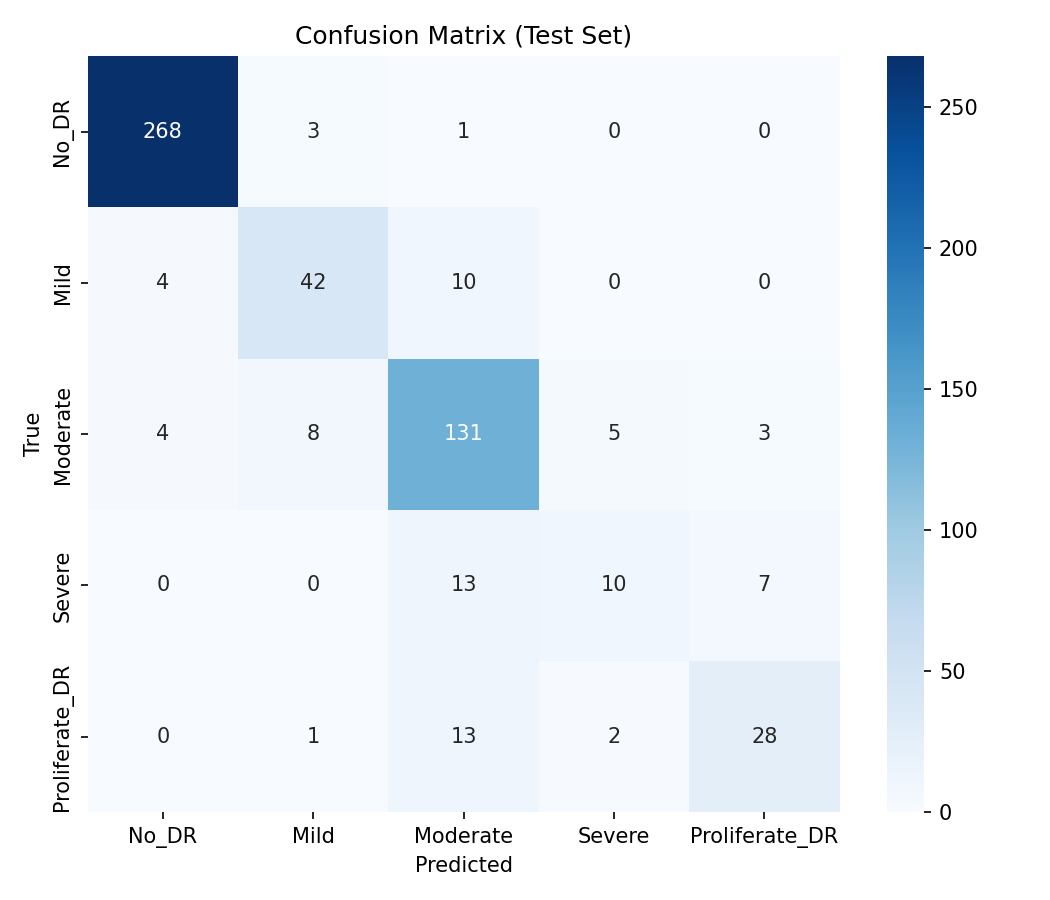

In [ ]:
from IPython.display import display
from PIL import Image

display(Image.open("outputs/confusion_matrix.png"))

In [ ]:
import json
import numpy as np

with open("outputs/classification_report.json") as f:
    report = json.load(f)

print("Use outputs/confusion_matrix.png for the plotted matrix.")
print("Class order:")
print(["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"])

Use outputs/confusion_matrix.png for the plotted matrix.
Class order:
['No_DR', 'Mild', 'Moderate', 'Severe', 'Proliferate_DR']


[[268   3   1   0   0]
 [  4  42  10   0   0]
 [  4   8 131   5   3]
 [  0   0  13  10   7]
 [  0   1  13   2  28]]


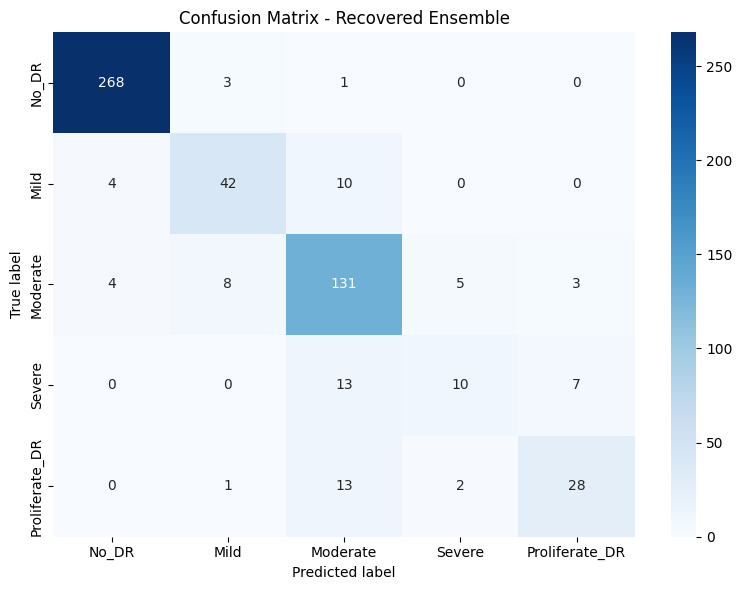

In [ ]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

from src.model import build_ensemble_model
from src.dataset import DRDataset, resolve_split_path, get_eval_transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "checkpoints/best_model_accuracy_RECOVERED.pth"

checkpoint = torch.load(checkpoint_path, map_location=device)

model = build_ensemble_model(
    num_classes=5,
    feature_layer=checkpoint.get("feature_layer", "layer3"),
    pretrained=False,
    resnet_weight=checkpoint.get("resnet_weight", 0.7),
    device=device,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

dataset = DRDataset(
    resolve_split_path("data/split", "test"),
    transform=get_eval_transforms(),
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
)

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

class_names = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR",
]

matrix = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
)

print(matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix - Recovered Ensemble")
plt.tight_layout()
plt.show()

In [ ]:
!python app.py

 * Serving Flask app 'app'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
Press CTRL+C to quit
